# 07 · Hyperparameter search

This notebook searches learning rate, dropout rate, and batch size in sequence, then trains one final CNN using the selected values. Each search keeps the earlier selected values fixed.


In [1]:
import matplotlib.pyplot as plt

from src.data import load_emnist
from src.preprocessing import preprocess_images
from src.models import create_cnn
from src.training import compile_model, create_early_stopping, fit_and_evaluate


I0000 00:00:1790113976.427883  125496 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790113976.495803  125496 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790113978.651520  125496 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Prepare the data

Load and normalize the images. Early stopping uses validation loss and restores the best weights during each experiment.


In [2]:
X_train, y_train, writers_train, X_test, y_test, writers_test = load_emnist()

X_train = preprocess_images(X_train)
X_test = preprocess_images(X_test)

In [3]:
early_stopping = create_early_stopping(patience=2)

## Compare learning rates

Train one model per candidate learning rate and compare their test metrics. The selected learning rate is passed into the next search.


In [4]:
learning_rates = [0.0001, 0.001, 0.01]
lr_results = {}

for learning_rate in learning_rates:
    print(f"\n{'=' * 20} Learning Rate: {learning_rate} {'=' * 20}")
    model = compile_model(create_cnn(dropout_rate=0.5), learning_rate=learning_rate)
    result = fit_and_evaluate(
        model, X_train, y_train, X_test, y_test,
        epochs=15, batch_size=128, callbacks=[early_stopping], verbose=1,
    )
    lr_results[learning_rate] = result
    print(f"Test accuracy: {result['test_accuracy']:.4f}")
    print(f"Test loss: {result['test_loss']:.4f}")



==================== Learning Rate: 0.0001 ====================


W0000 00:00:1790113981.590169  125496 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 36s 21ms/step - accuracy: 0.8895 - loss: 0.3792 - val_accuracy: 0.9733 - val_loss: 0.0912
Epoch 2/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.9671 - loss: 0.1158 - val_accuracy: 0.9816 - val_loss: 0.0614
Epoch 3/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.9755 - loss: 0.0860 - val_accuracy: 0.9839 - val_loss: 0.0522
Epoch 4/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.9798 - loss: 0.0714 - val_accuracy: 0.9865 - val_loss: 0.0440
Epoch 5/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.9825 - loss: 0.0615 - val_accuracy: 0.9884 - val_loss: 0.0381
Epoch 6/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.9839 - loss: 0.0574 - val_accuracy: 0.9889 - val_loss: 0.0366
Epoch 7/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9851 - loss: 0.0516 - val_accuracy: 0.9897 - val_loss: 0.0331
Epoch 8/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9864 -

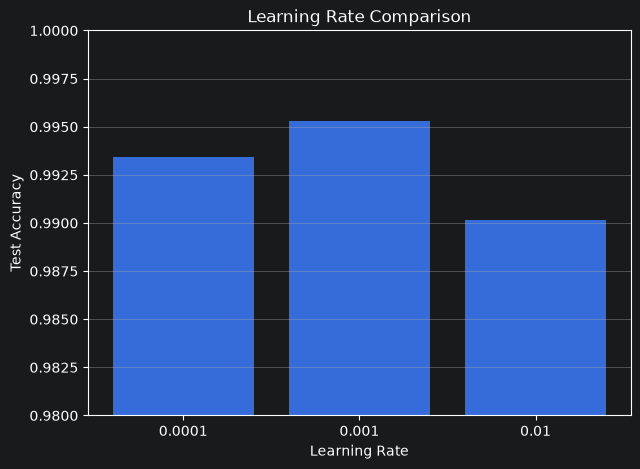

In [5]:
lr_accuracy = {
    str(lr): result["test_accuracy"]
    for lr, result in lr_results.items()
}

plt.figure(figsize=(7, 5))
plt.bar(lr_accuracy.keys(), lr_accuracy.values())

plt.xlabel("Learning Rate")
plt.ylabel("Test Accuracy")
plt.title("Learning Rate Comparison")
plt.ylim(0.98, 1.0)
plt.grid(axis="y")

plt.show()

In [6]:
best_learning_rate = max(
    lr_results,
    key=lambda lr: lr_results[lr]["test_accuracy"]
)

print(f"Best learning rate: {best_learning_rate}")

Best learning rate: 0.001


## Compare dropout rates

With the selected learning rate fixed, compare the dropout candidates.


In [7]:
dropout_rates = [0.0, 0.3, 0.5]
dropout_results = {}

for dropout_rate in dropout_rates:
    print(f"\n{'=' * 20} Dropout: {dropout_rate} {'=' * 20}")
    model = compile_model(create_cnn(dropout_rate=dropout_rate), learning_rate=best_learning_rate)
    result = fit_and_evaluate(
        model, X_train, y_train, X_test, y_test,
        epochs=15, batch_size=128, callbacks=[early_stopping], verbose=1,
    )
    dropout_results[dropout_rate] = result
    print(f"Test accuracy: {result['test_accuracy']:.4f}")
    print(f"Test loss: {result['test_loss']:.4f}")



==================== Dropout: 0.0 ====================
Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9749 - loss: 0.0849 - val_accuracy: 0.9901 - val_loss: 0.0323
Epoch 2/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9919 - loss: 0.0277 - val_accuracy: 0.9910 - val_loss: 0.0297
Epoch 3/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9939 - loss: 0.0207 - val_accuracy: 0.9923 - val_loss: 0.0246
Epoch 4/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9952 - loss: 0.0162 - val_accuracy: 0.9937 - val_loss: 0.0209
Epoch 5/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9963 - loss: 0.0123 - val_accuracy: 0.9938 - val_loss: 0.0211
Epoch 6/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9972 - loss: 0.0098 - val_accuracy: 0.9937 - val_loss: 0.0226
Test accuracy: 0.9946
Test loss: 0.0182

==================== Dropout: 0.3 ====================
Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step 

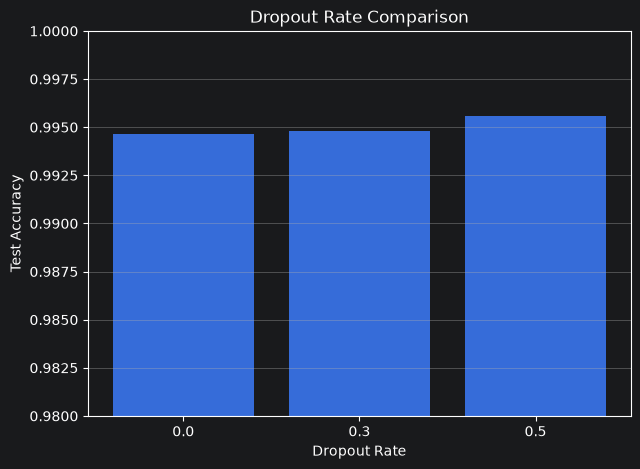

In [8]:
dropout_accuracy = {
    str(rate): result["test_accuracy"]
    for rate, result in dropout_results.items()
}

plt.figure(figsize=(7, 5))
plt.bar(dropout_accuracy.keys(), dropout_accuracy.values())

plt.xlabel("Dropout Rate")
plt.ylabel("Test Accuracy")
plt.title("Dropout Rate Comparison")
plt.ylim(0.98, 1.0)
plt.grid(axis="y")

plt.show()

In [9]:
best_dropout_rate = max(
    dropout_results,
    key=lambda rate: dropout_results[rate]["test_accuracy"]
)

print(f"Best dropout rate: {best_dropout_rate}")

Best dropout rate: 0.5


## Compare batch sizes

With the selected learning rate and dropout rate fixed, compare the batch size candidates.


In [10]:
batch_sizes = [64, 128, 256]
batch_results = {}

for batch_size in batch_sizes:
    print(f"\n{'=' * 20} Batch Size: {batch_size} {'=' * 20}")
    model = compile_model(create_cnn(dropout_rate=best_dropout_rate), learning_rate=best_learning_rate)
    result = fit_and_evaluate(
        model, X_train, y_train, X_test, y_test,
        epochs=15, batch_size=batch_size, callbacks=[early_stopping], verbose=1,
    )
    batch_results[batch_size] = result
    print(f"Test accuracy: {result['test_accuracy']:.4f}")
    print(f"Test loss: {result['test_loss']:.4f}")



==================== Batch Size: 64 ====================
Epoch 1/15
3375/3375 ━━━━━━━━━━━━━━━━━━━━ 26s 8ms/step - accuracy: 0.9686 - loss: 0.1062 - val_accuracy: 0.9912 - val_loss: 0.0299
Epoch 2/15
3375/3375 ━━━━━━━━━━━━━━━━━━━━ 25s 7ms/step - accuracy: 0.9884 - loss: 0.0411 - val_accuracy: 0.9925 - val_loss: 0.0251
Epoch 3/15
3375/3375 ━━━━━━━━━━━━━━━━━━━━ 25s 7ms/step - accuracy: 0.9911 - loss: 0.0314 - val_accuracy: 0.9933 - val_loss: 0.0236
Epoch 4/15
3375/3375 ━━━━━━━━━━━━━━━━━━━━ 25s 7ms/step - accuracy: 0.9923 - loss: 0.0268 - val_accuracy: 0.9943 - val_loss: 0.0203
Epoch 5/15
3375/3375 ━━━━━━━━━━━━━━━━━━━━ 25s 7ms/step - accuracy: 0.9937 - loss: 0.0228 - val_accuracy: 0.9941 - val_loss: 0.0235
Epoch 6/15
3375/3375 ━━━━━━━━━━━━━━━━━━━━ 25s 7ms/step - accuracy: 0.9941 - loss: 0.0204 - val_accuracy: 0.9944 - val_loss: 0.0213
Test accuracy: 0.9954
Test loss: 0.0176

==================== Batch Size: 128 ====================
Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step -

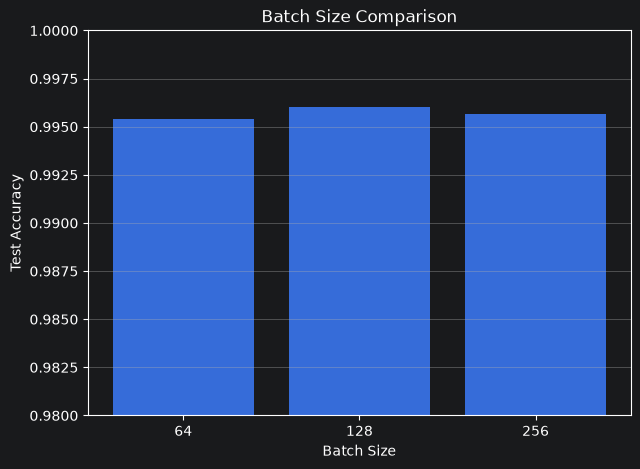

In [11]:
batch_accuracy = {
    str(batch_size): result["test_accuracy"]
    for batch_size, result in batch_results.items()
}

plt.figure(figsize=(7, 5))
plt.bar(batch_accuracy.keys(), batch_accuracy.values())

plt.xlabel("Batch Size")
plt.ylabel("Test Accuracy")
plt.title("Batch Size Comparison")
plt.ylim(0.98, 1.0)
plt.grid(axis="y")

plt.show()

In [12]:
best_batch_size = max(
    batch_results,
    key=lambda batch_size: batch_results[batch_size]["test_accuracy"]
)

print(f"Best batch size: {best_batch_size}")

Best batch size: 128


## Record the selected settings

These values are used to train and evaluate the final model in the cells below.


In [13]:
print("Selected hyperparameters")
print("------------------------")
print(f"Learning rate : {best_learning_rate}")
print(f"Dropout rate  : {best_dropout_rate}")
print(f"Batch size    : {best_batch_size}")

Selected hyperparameters
------------------------
Learning rate : 0.001
Dropout rate  : 0.5
Batch size    : 128


## Final model

Train the CNN with the selected settings, evaluate it, and save the model file.


In [14]:
final_model = compile_model(create_cnn(dropout_rate=best_dropout_rate), learning_rate=best_learning_rate)
final_result = fit_and_evaluate(
    final_model, X_train, y_train, X_test, y_test,
    epochs=15, batch_size=best_batch_size, callbacks=[early_stopping], verbose=1,
)
final_history = final_result["history"]


Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.9624 - loss: 0.1279 - val_accuracy: 0.9905 - val_loss: 0.0317
Epoch 2/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9867 - loss: 0.0471 - val_accuracy: 0.9920 - val_loss: 0.0248
Epoch 3/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9902 - loss: 0.0354 - val_accuracy: 0.9937 - val_loss: 0.0208
Epoch 4/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9916 - loss: 0.0289 - val_accuracy: 0.9935 - val_loss: 0.0235
Epoch 5/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9927 - loss: 0.0253 - val_accuracy: 0.9944 - val_loss: 0.0198
Epoch 6/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9937 - loss: 0.0220 - val_accuracy: 0.9948 - val_loss: 0.0192
Epoch 7/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.9944 - loss: 0.0195 - val_accuracy: 0.9946 - val_loss: 0.0205
Epoch 8/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9951 -

In [15]:
final_test_loss = final_result["test_loss"]
final_test_accuracy = final_result["test_accuracy"]
print(f"Final test accuracy: {final_test_accuracy:.4f}")
print(f"Final test loss: {final_test_loss:.4f}")


Final test accuracy: 0.9953
Final test loss: 0.0181


In [16]:
final_model.save("../models/cnn_tuned.keras")

## Results and interpretation

The saved search selected a learning rate of **0.001**, dropout rate **0.5**, and batch size **128**. The final run reached **99.53%** test accuracy with **0.0181** test loss.

The current search chooses settings by test accuracy at each stage, so the test set influences model selection. Treat the final score as exploratory; for an unbiased final estimate, choose settings using validation results and evaluate on the test set once.
